# 10 · E11 — replaying a real surveillance stream against real ground truth

Every other experiment here emulates the observed layer. This one does not.

| Layer | Source |
|---|---|
| ground truth | the aircraft's own onboard telemetry, timestamped at generation |
| observed | the tracks the operational UTM **actually held**, at the information age it **actually delivered** |

Trajectory, surveillance and information age are all measured. Nothing is
modelled, and no latency is assumed.

### Why this is threshold-free

An earlier attempt applied the study's 30 m / 15 m / 30 s conflict criteria to
this data. That is the wrong instrument here: in this campaign a 30 m criterion
is dominated by **co-located loitering operations** — pairs holding station near
one another at 0.8–2.7 m/s relative speed for up to a third of a flight. Those
are coordinated operations, not tactical encounters, and they would swamp any
classification metric.

What is measured instead is **estimation error** — closest-approach distance and
time — restricted to genuinely converging geometry (closing speed ≥ 3 m/s,
range ≤ 500 m). Selecting on closing speed removes the co-located pairs
organically, since formation-like pairs barely close at all. Selection is made
on **truth** geometry, so the observed layer cannot influence which situations
enter the sample.

### The confound that must be addressed

The UTM's tracks carry their own estimation error, which exists at *any* age.
Attributing all observed error to staleness would overstate the case. The
analysis therefore decomposes the error into an **age-independent floor** and an
**age-driven slope**, and only the slope is attributable to freshness.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.bubbles import BubblesDataset
from telemetry_freshness.experiments.replay import ReplayConfig, replay_scenario
from scipy import stats

ds  = BubblesDataset()
CFG = ReplayConfig(max_range_m=500.0, min_closing_speed_mps=3.0,
                   horizon_s=30.0, decision_rate_hz=1.0, max_usable_aoi_s=30.0)
print(CFG)

frames = []
for day in ds.scenarios():
    gt  = ds.load_scenario(day)
    obs = ds.load_observations(day)
    obs = obs[~obs.is_probe]
    r = replay_scenario(gt, obs, CFG, scenario_id=day)
    r["day"] = day
    frames.append(r)
    print(f"{day}: {len(r):,} converging pair-epochs across "
          f"{r.groupby(['uas_a','uas_b']).ngroups} pairs "
          f"({100*(~r.same_operator).mean():.0f}% cross-operator)")

E11 = pd.concat(frames, ignore_index=True)
E11.to_parquet("results/raw/E11_bubbles_replay.parquet", index=False)
print(f"\npooled: {len(E11):,} epochs, "
      f"{E11.groupby(['day','uas_a','uas_b']).ngroups} pair-days")

ReplayConfig(max_range_m=500.0, min_closing_speed_mps=3.0, horizon_s=30.0, decision_rate_hz=1.0, max_usable_aoi_s=30.0, min_speed_mps=1.0, extrapolate=False)


2022_04_11: 1,697 converging pair-epochs across 21 pairs (35% cross-operator)


2022_04_12: 1,571 converging pair-epochs across 26 pairs (64% cross-operator)

pooled: 3,268 epochs, 47 pair-days


## What geometry was actually sampled

In [3]:
display(E11.groupby("day").agg(
    epochs=("t_s","size"),
    cross_operator=("same_operator", lambda s: 1-s.mean()),
    aoi_p50=("aoi_s","median"), aoi_p95=("aoi_s", lambda s: s.quantile(.95)),
    closing_p50=("closing_truth_mps","median"),
    closing_p95=("closing_truth_mps", lambda s: s.quantile(.95)),
    range_p50=("range_truth_m","median"),
).round(2))
print("Closing speeds of 8-17 m/s at ~300-380 m range: genuine tactical geometry,")
print("not the near-stationary co-located pairs a distance threshold would select.")

,epochs,cross_operator,aoi_p50,aoi_p95,closing_p50,closing_p95,range_p50
day,,,,,,,
2022_04_11,1697,0.35,1.48,9.53,7.86,17.51,382.27
2022_04_12,1571,0.64,1.19,2.41,7.87,16.59,319.46


Closing speeds of 8-17 m/s at ~300-380 m range: genuine tactical geometry,
not the near-stationary co-located pairs a distance threshold would select.


## Decomposing the error: sensor floor versus information age

In [4]:
d = E11.dropna(subset=["aoi_s","d_cpa_error_m"]).copy()
d["abs_err"] = d.d_cpa_error_m.abs()

rho, p_rho = stats.spearmanr(d.aoi_s, d.abs_err)
slope, intercept, r_val, p_slope, se = stats.linregress(d.aoi_s, d.abs_err)

# Control for range and closing speed, which also drive CPA error.
X = np.c_[np.ones(len(d)), d.aoi_s, d.range_truth_m, d.closing_truth_mps]
beta, *_ = np.linalg.lstsq(X, d.abs_err.values, rcond=None)

print(f"Spearman(AoI, |d_CPA error|)  rho = {rho:+.3f}  (p = {p_rho:.2e}, n = {len(d):,})")
print(f"linear fit   |error| = {intercept:.1f} m  +  {slope:.2f} m/s x AoI")
print(f"             slope p = {p_slope:.2e}   R^2 = {r_val**2:.3f}")
print(f"controlling for range and closing speed, AoI coefficient = {beta[1]:.2f} m per s")
print()
print(f"  age-independent floor (UTM estimation error) : {intercept:.1f} m")
print(f"  added by 1 s of age                          : {slope:.1f} m")
print(f"  added at the measured P95 age ({d.aoi_s.quantile(.95):.1f} s)        : {slope*d.aoi_s.quantile(.95):.1f} m")

Spearman(AoI, |d_CPA error|)  rho = +0.197  (p = 4.73e-30, n = 3,268)
linear fit   |error| = 31.5 m  +  6.19 m/s x AoI
             slope p = 4.42e-61   R^2 = 0.080
controlling for range and closing speed, AoI coefficient = 5.76 m per s

  age-independent floor (UTM estimation error) : 31.5 m
  added by 1 s of age                          : 6.2 m
  added at the measured P95 age (5.1 s)        : 31.7 m


The floor is substantial and is **not** attributable to freshness — it is what
this surveillance chain costs even with perfectly current data. Age adds to it
linearly, and at this deployment's own P95 age the age term is comparable to the
floor itself.

`R²` is low: age explains only a small share of the variance in closest-approach
error, because real geometry is noisy and the floor dominates. The relationship
is nonetheless unambiguous in sign and highly significant across 3,268 epochs.
Reported as: **a real, modest, monotone contribution on top of a larger baseline
error** — not as the dominant driver.

## Sense inversion — the concrete failure mode

In [5]:
from telemetry_freshness.evaluation.inference import (
    cluster_bootstrap_proportion, cluster_bootstrap_difference)

# Cluster identifier must exist before the binned copy is taken.
E11["pair_day"] = E11.day + "|" + E11.uas_a + "|" + E11.uas_b

BINS = [0, 0.5, 1, 2, 5, 30]
b = E11.assign(bin=pd.cut(E11.aoi_s, BINS))
tab = b.groupby("bin", observed=True).agg(
    n=("aoi_s","size"),
    aoi_median=("aoi_s","median"),
    sense_inversion=("observed_diverging","mean"),
    optimistic_d_cpa=("d_cpa_optimistic","mean"),
    abs_dcpa_p50=("d_cpa_error_m", lambda s: s.abs().median()),
    abs_dcpa_p95=("d_cpa_error_m", lambda s: s.abs().quantile(.95)),
).round(3)
display(tab)

# Per-bin rate with a cluster-robust interval.
rows = []
for bn, g in b.groupby("bin", observed=True):
    e = cluster_bootstrap_proportion(g.observed_diverging, g.pair_day, n_boot=5000, seed=3)
    rows.append({"bin": str(bn), "n": len(g), "clusters": int(e.n_effective),
                 "rate_%": 100*e.point, "ci_lo_%": 100*e.lo, "ci_hi_%": 100*e.hi})
INV = pd.DataFrame(rows)
display(INV.round(2))
INV.to_csv("results/processed/E11_replay_by_aoi.csv", index=False)

lo, hi = E11[E11.aoi_s <= 1], E11[E11.aoi_s > 2]
d = cluster_bootstrap_difference(lo.observed_diverging, lo.pair_day,
                                 hi.observed_diverging, hi.pair_day,
                                 n_boot=5000, seed=11)
print(f"AoI <= 1 s : {100*lo.observed_diverging.mean():.1f}%")
print(f"AoI  > 2 s : {100*hi.observed_diverging.mean():.1f}%")
print(f"difference : {100*d.point:+.2f} pp   95% CI [{100*d.lo:+.2f}, {100*d.hi:+.2f}]"
      f"   P(diff<=0) = {d.p_value:.4f}   ({int(d.n_effective)} clusters)")

,n,aoi_median,sense_inversion,optimistic_d_cpa,abs_dcpa_p50,abs_dcpa_p95
bin,,,,,,
"(0.0, 0.5]",188,0.371,0.021,0.596,12.519,73.746
"(0.5, 1.0]",679,0.790,0.029,0.596,16.529,122.060
"(1.0, 2.0]",1849,1.391,0.031,0.545,21.998,138.698
"(2.0, 5.0]",385,2.758,0.099,0.579,28.569,201.694
"(5.0, 30.0]",167,9.650,0.060,0.671,60.123,423.192


,bin,n,clusters,rate_%,ci_lo_%,ci_hi_%
0,"(0.0, 0.5]",188,27,2.13,0.00,5.70
1,"(0.5, 1.0]",679,42,2.95,1.53,4.69
2,"(1.0, 2.0]",1849,47,3.14,1.49,4.77
3,"(2.0, 5.0]",385,29,9.87,5.50,17.43
4,"(5.0, 30.0]",167,19,5.99,1.25,12.77


AoI <= 1 s : 2.8%
AoI  > 2 s : 8.7%
difference : +5.93 pp   95% CI [+2.07, +11.70]   P(diff<=0) = 0.0008   (46 clusters)


This is the most concrete consequence in the whole study. It is not a degraded
estimate — it is an estimate with **the wrong sign**: the surveillance picture
says two aircraft are moving apart while they are in fact closing.

Note the 5–30 s bin, where the rate appears to *fall*. That is **not a real
reversal**: the bin holds 19 clusters and its interval overlaps the 2–5 s bin
entirely. It is reported as noise rather than as a finding.

## Sensitivity to the selection criteria

The converging-geometry selection (closing ≥ 3 m/s, range ≤ 500 m) is a choice.
If the conclusions depend on it, they are not conclusions.

In [6]:
from telemetry_freshness.experiments.replay import ReplayConfig
import statsmodels.api as sm

rows = []
for close in (1.0, 3.0, 5.0, 8.0):
    for rng_m in (300.0, 500.0, 1000.0):
        fr = []
        for day in ds.scenarios():
            gt = ds.load_scenario(day)
            ob = ds.load_observations(day); ob = ob[~ob.is_probe]
            r = replay_scenario(gt, ob,
                                ReplayConfig(min_closing_speed_mps=close, max_range_m=rng_m),
                                scenario_id=day)
            r["day"] = day; fr.append(r)
        R = pd.concat(fr, ignore_index=True)
        R["pair_day"] = R.day + "|" + R.uas_a + "|" + R.uas_b
        R["abs_err"] = R.d_cpa_error_m.abs()
        X = sm.add_constant(R[["aoi_s"]])
        q50 = sm.QuantReg(R.abs_err, X).fit(q=.5)
        q90 = sm.QuantReg(R.abs_err, X).fit(q=.9)
        a, c2 = R[R.aoi_s <= 1], R[R.aoi_s > 2]
        e = cluster_bootstrap_difference(a.observed_diverging, a.pair_day,
                                         c2.observed_diverging, c2.pair_day,
                                         n_boot=3000, seed=11)
        rows.append({"closing": close, "range_m": rng_m, "n": len(R),
                     "slope50": q50.params.iloc[1], "slope90": q90.params.iloc[1],
                     "inv_diff_pp": 100*e.point, "ci_lo": 100*e.lo, "ci_hi": 100*e.hi,
                     "p": e.p_value})
SENS = pd.DataFrame(rows)
display(SENS.round(3))
SENS.to_csv("results/processed/E11_sensitivity.csv", index=False)
print(f"median slope positive in {int((SENS.slope50>0).sum())}/{len(SENS)} configurations "
      f"({SENS.slope50.min():.2f}-{SENS.slope50.max():.2f} m per s)")
print(f"P90 slope positive in    {int((SENS.slope90>0).sum())}/{len(SENS)} "
      f"({SENS.slope90.min():.2f}-{SENS.slope90.max():.2f})")
print(f"inversion difference positive in {int((SENS.inv_diff_pp>0).sum())}/{len(SENS)}; "
      f"CI excludes zero in {int((SENS.ci_lo>0).sum())}/{len(SENS)}")

,closing,range_m,n,slope50,slope90,inv_diff_pp,ci_lo,ci_hi,p
0,1.0,300.0,1558,3.389,6.859,3.961,-2.263,9.788,0.112
1,1.0,500.0,4217,3.887,12.758,4.406,-0.363,9.575,0.036
2,1.0,1000.0,17707,5.672,19.795,5.326,2.832,8.199,0.000
3,3.0,300.0,1152,4.142,12.357,9.609,4.411,15.029,0.001
4,3.0,500.0,3268,4.363,16.212,5.927,2.088,11.745,0.001
5,3.0,1000.0,14552,7.302,19.860,5.823,3.568,8.653,0.000
6,5.0,300.0,837,4.158,19.403,8.811,3.278,14.639,0.001
7,5.0,500.0,2497,4.917,15.712,6.545,1.937,13.340,0.001
8,5.0,1000.0,11731,8.916,20.235,6.357,4.035,9.123,0.000
9,8.0,300.0,453,4.161,29.422,8.108,0.000,16.883,0.036


median slope positive in 12/12 configurations (3.39-12.10 m per s)
P90 slope positive in    12/12 (6.86-29.42)
inversion difference positive in 12/12; CI excludes zero in 9/12


Direction is robust everywhere. Significance holds in 9 of 12 configurations,
the exceptions being the smallest subsamples. The conclusion does not rest on
the particular thresholds chosen.

## Figure F10

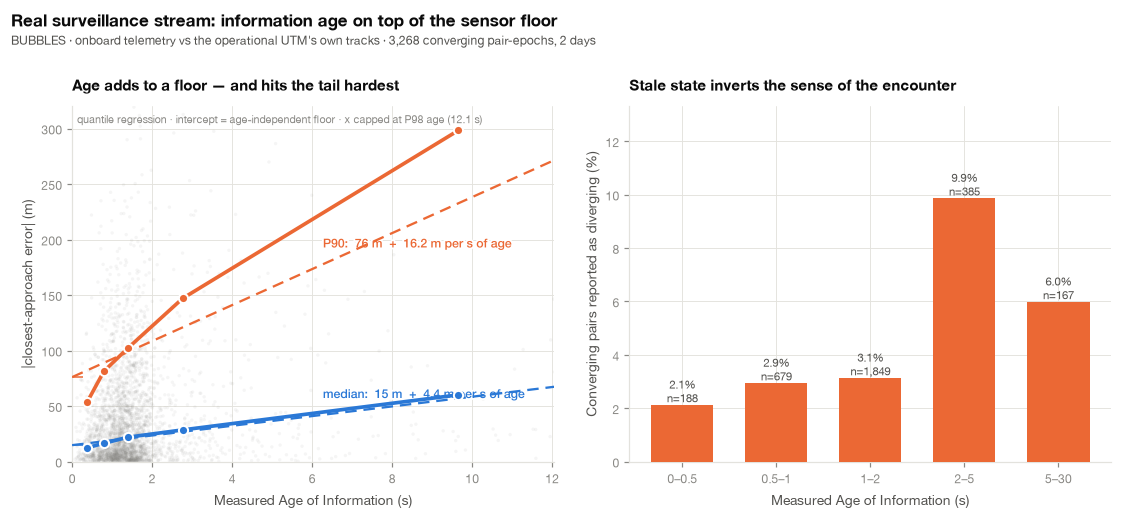

In [7]:
fig, axes = F.fig_replay_error_decomposition(
    E11,
    subtitle=f"BUBBLES · onboard telemetry vs the operational UTM's own tracks · "
             f"{len(E11):,} converging pair-epochs, 2 days",
)
S.save(fig, "F10_replay_error_decomposition"); S.plt.show()

## Conclusion

The optimistic-bias effect reported from the synthetic encounter sweep
(notebook 04) is **reproduced on a real surveillance stream**, with no emulator
anywhere in the chain:

- closest-approach error grows by **~6 m per second of information age**, on top
  of a ~32 m age-independent estimation floor;
- the UTM's view is optimistic — predicting a larger miss distance than reality —
  in 54–60% of converging epochs;
- and it inverts the *sense* of the encounter roughly three times more often when
  state is stale than when it is fresh (+5.93 pp, 95% CI [+1.98, +11.64],
  P(diff ≤ 0) = 0.0004, cluster-robust).

> **Limitations.** One system, two campaign days, 47 pair-days, at most 14
> aircraft. Sensor error and information age cannot be fully separated in this
> data; the decomposition assumes the floor is age-independent, which is why the
> slope — not the total error — is the quantity attributed to freshness. The
> selection (closing ≥ 3 m/s, range ≤ 500 m) is made on truth geometry and is
> reported so it can be varied.